In [22]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import os
from tensorflow.keras.utils import to_categorical

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
%matplotlib inline

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

from keras.applications.densenet import DenseNet121
from keras.layers import Dense
from keras.models import Sequential

from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
# Load and preprocess data
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0

In [5]:
labels = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

In [6]:
# Transform target variable into one-hotencoding
y_cat_train = to_categorical(y_train, 10)
y_cat_test = to_categorical(y_test, 10)

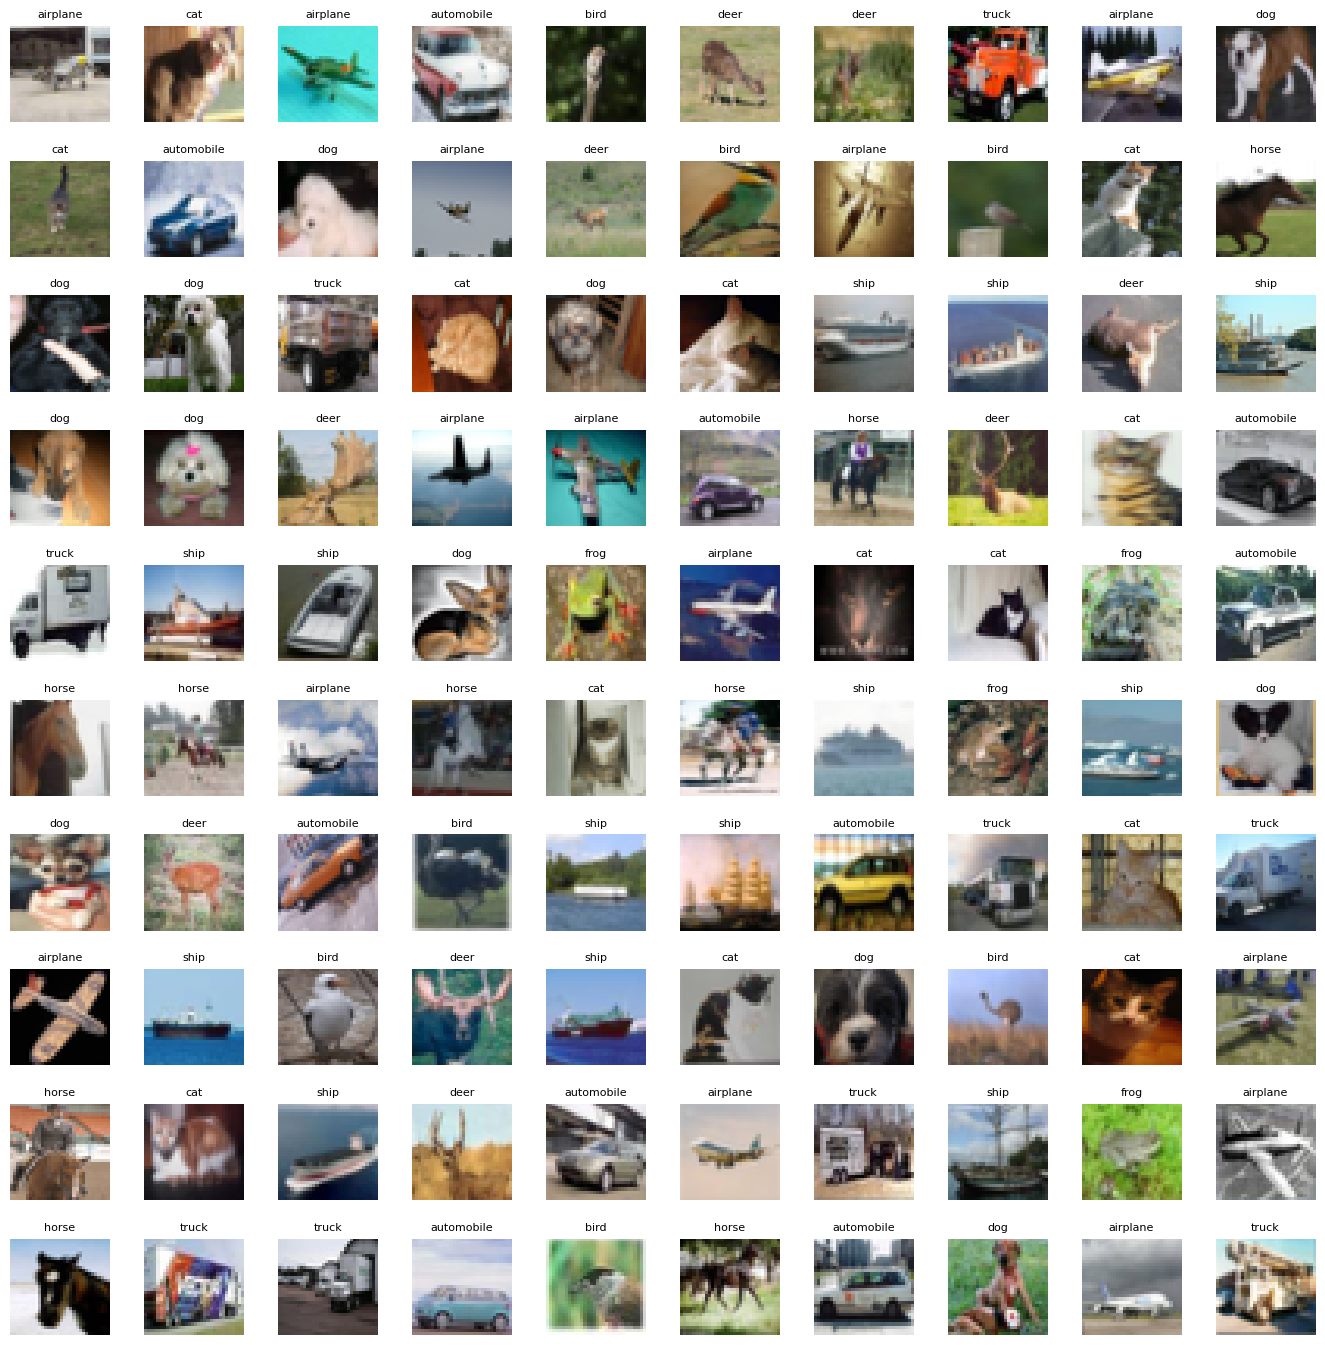

In [7]:
# Data Visualization
# Let's view more images in a grid format
# Define the dimensions of the plot grid 
W_grid = 10
L_grid = 10

# fig, axes = plt.subplots(L_grid, W_grid)
# subplot return the figure object and axes object
# we can use the axes object to plot specific figures at various locations

fig, axes = plt.subplots(L_grid, W_grid, figsize = (17,17))

axes = axes.ravel() # flaten the 15 x 15 matrix into 225 array

n_train = len(X_train) # get the length of the train dataset

# Select a random number from 0 to n_train
for i in np.arange(0, W_grid * L_grid): # create evenly spaces variables 

    # Select a random number
    index = np.random.randint(0, n_train)
    # read and display an image with the selected index    
    axes[i].imshow(X_train[index,1:])
    label_index = int(y_train[index])
    axes[i].set_title(labels[label_index], fontsize = 8)
    axes[i].axis('off')

plt.subplots_adjust(hspace=0.4)

In [15]:
model_path = "cnn_20_ephochs_model.h5"
if os.path.exists(model_path):
    # Load the model if it exists
    model = tf.keras.models.load_model(model_path)
    print("Model loaded from disk.")
else:
    model = Sequential()
    base_model = DenseNet121(input_shape=(32, 32, 3), include_top=False, weights='imagenet', pooling='avg')
    model.add(base_model)
    model.add(Dense(10, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    model.summary()
    batch_size = 32
    data_generator = ImageDataGenerator(width_shift_range=0.1, height_shift_range=0.1, horizontal_flip=True)
    train_generator = data_generator.flow(X_train, y_cat_train, batch_size)
    steps_per_epoch = X_train.shape[0] // batch_size
    
    r = model.fit(train_generator, 
                  epochs=30,
                  steps_per_epoch=steps_per_epoch,
                  validation_data=(X_test, y_cat_test), 
    #               callbacks=[early_stop],
                 )
    # Save the model
    model.save(model_path)
    print("Model saved to disk.")

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 densenet121 (Functional)    (None, 1024)              7037504   
                                                                 
 dense_3 (Dense)             (None, 10)                10250     
                                                                 
Total params: 7047754 (26.89 MB)
Trainable params: 6964106 (26.57 MB)
Non-trainable params: 83648 (326.75 KB)
_________________________________________________________________
Epoch 1/30


2026-03-11 18:38:44.909183: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1562/1562 [==============================] - ETA: 0s - loss: 1.2619 - accuracy: 0.5746     

2026-03-11 18:40:32.649373: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1562/1562 [==============================] - 117s 72ms/step - loss: 1.2619 - accuracy: 0.5746 - val_loss: 1.9916 - val_accuracy: 0.4132
Epoch 2/30
1562/1562 [==============================] - 110s 70ms/step - loss: 0.9640 - accuracy: 0.6792 - val_loss: 1.1944 - val_accuracy: 0.6098
Epoch 3/30
1562/1562 [==============================] - 111s 71ms/step - loss: 1.1620 - accuracy: 0.6072 - val_loss: 1.0652 - val_accuracy: 0.6306
Epoch 4/30
1562/1562 [==============================] - 114s 73ms/step - loss: 1.1923 - accuracy: 0.5982 - val_loss: 1.2512 - val_accuracy: 0.5962
Epoch 5/30
1562/1562 [==============================] - 114s 73ms/step - loss: 1.0075 - accuracy: 0.6581 - val_loss: 1.2006 - val_accuracy: 0.6712
Epoch 6/30
1562/1562 [==============================] - 113s 72ms/step - loss: 0.8415 - accuracy: 0.7127 - val_loss: 1.1235 - val_accuracy: 0.7169
Epoch 7/30
1562/1562 [==============================] - 115s 73ms/step - loss: 0.7204 - accuracy: 0.7547 - val_loss: 0.8633 - val

/opt/anaconda3/envs/tf2/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model saved to disk.


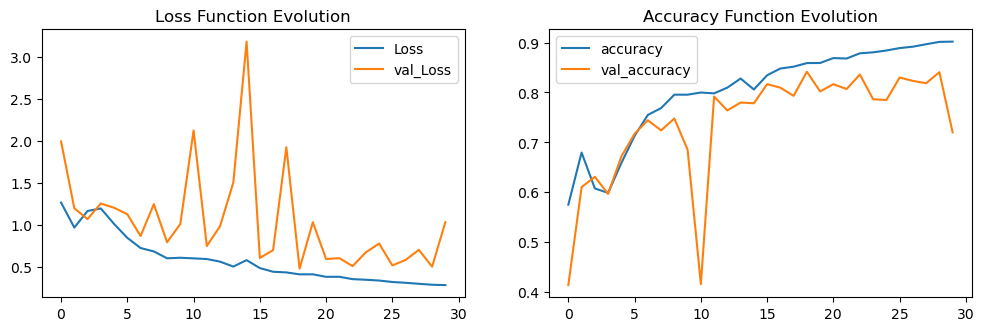

In [20]:
# Model Evaluation
plt.figure(figsize=(12, 16))

plt.subplot(4, 2, 1)
plt.plot(r.history['loss'], label='Loss')
plt.plot(r.history['val_loss'], label='val_Loss')
plt.title('Loss Function Evolution')
plt.legend()

plt.subplot(4, 2, 2)
plt.plot(r.history['accuracy'], label='accuracy')
plt.plot(r.history['val_accuracy'], label='val_accuracy')
plt.title('Accuracy Function Evolution')
plt.legend()


313/313 [==============================] - 6s 19ms/step - loss: 1.0287 - accuracy: 0.7196
Test Accuracy : 71.96%


2026-03-11 19:52:14.090386: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


313/313 [==============================] - 6s 16ms/step


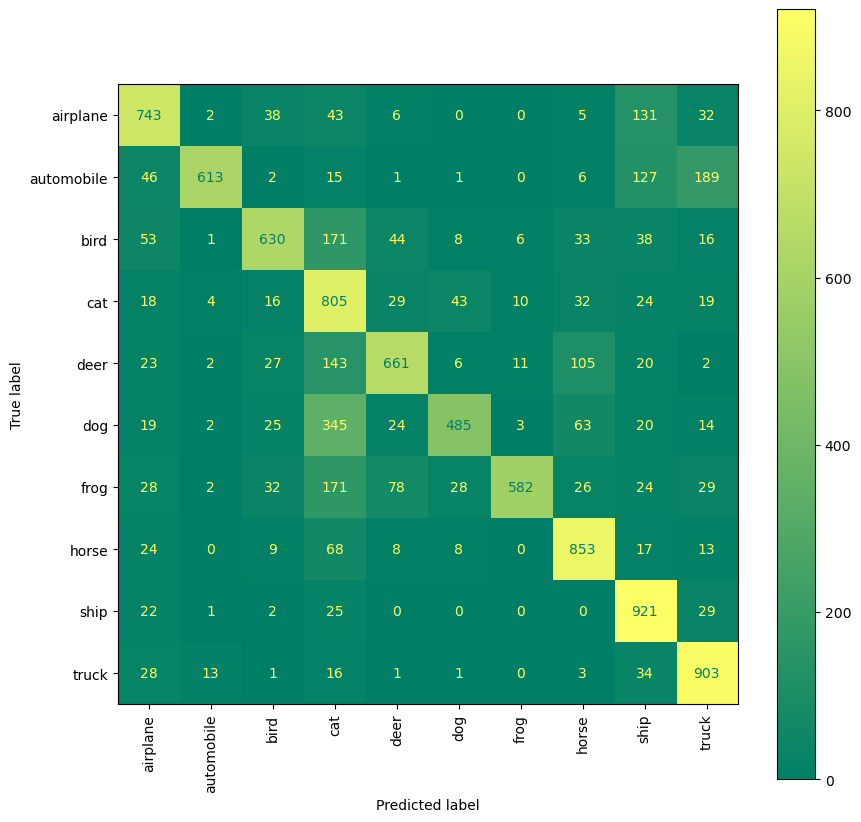

In [21]:
evaluation = model.evaluate(X_test, y_cat_test)
print(f'Test Accuracy : {evaluation[1] * 100:.2f}%')

y_pred = model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)
cm = confusion_matrix(y_test, y_pred)


disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=labels)


# NOTE: Fill all variables here with default values of the plot_confusion_matrix
fig, ax = plt.subplots(figsize=(10, 10))
disp = disp.plot(xticks_rotation='vertical', ax=ax,cmap='summer')

plt.show()

 Image 100 is airplane
1/1 [==============================] - 0s 31ms/step
The model predict that image is  airplane


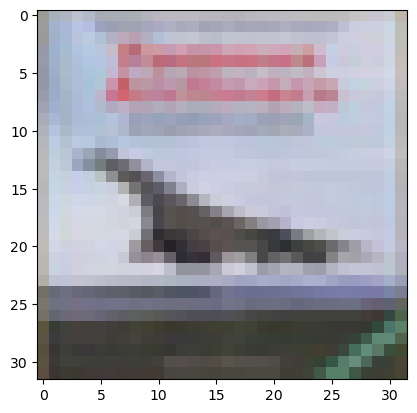

In [37]:
# Test on one image
image_id = 3
my_image = X_test[image_id]
plt.imshow(my_image)

test_label = labels[y_test[image_id][0]]
print(f" Image 100 is",test_label)

# correctly predicted as a Deer
pred_100 = np.argmax(model.predict(my_image.reshape(1, 32, 32, 3)))
pred_label = labels[pred_100]
print(f"The model predict that image is ",pred_label)